###  Cách triển khai mô hình hiện tại:
- **Tuning** sử dụng GridSearchCV để tìm ra parameter tốt nhất
- **Sử dụng k-fold validate** để tránh overfiting
- Xử lý mất cân bằng bằng cách sử dụng tham số `class_weight` hoặc `scale_pos_weight` trong mô hình. **Không áp dụng** các kỹ thuật **resampling** như SMOTE hay UnderSampler để xử lý mất cân bằng.
- **Chưa tối ưu ngưỡng phân loại (threshold)**, đang sử dụng ngưỡng mặc định là **0.5**. Điều này khiến việc đánh giá F1-score có thể chưa công bằng và chưa phản ánh đúng năng lực mô hình.

In [ ]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 9.0 MB/s eta 0:00:00


In [ ]:
!pip install shap xgboost

In [ ]:
import os
import gc
from glob import glob
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import polars as pl

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.model_selection import StratifiedGroupKFold, KFold, cross_val_predict, StratifiedKFold, GridSearchCV
from sklearn.base import BaseEstimator, ClassifierMixin
import catboost as cb
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier,StackingClassifier, VotingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.linear_model import LogisticRegression
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.metrics import confusion_matrix, recall_score, precision_score, accuracy_score, roc_curve, auc,f1_score, roc_auc_score, classification_report
from sklearn.utils.class_weight import compute_class_weight
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTETomek
from collections import Counter
import warnings
import time
warnings.simplefilter(action='ignore', category=FutureWarning)

pd.set_option('display.max_columns', None)

## Preprocessing

### Load data

In [ ]:
from google.colab import drive
root_drive='/content/drive'
drive.mount(root_drive, force_remount=True)

Mounted at /content/drive


In [ ]:
df = pd.read_csv('/content/drive/MyDrive/KhoaLuan/Data/df_cleaned.csv', nrows=None)

In [ ]:
df = df.drop(columns=['Unnamed: 0'])
print("Dữ liệu có dạng:", df.shape)
df.head()

Dữ liệu có dạng: (291057, 28)


,TARGET,EXT_SOURCE_MEAN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,BURO_AMT_CREDIT_SUM_DEBT_MEAN,BURO_AMT_CREDIT_SUM_MEAN,BURO_AMT_CREDIT_MAX_OVERDUE_MEAN,PREV_AMT_ANNUITY_MEAN,PREV_CNT_PAYMENT_SUM,PREV_APP_CREDIT_PERC_MIN,INST_DPD_MEAN,INST_PAYMENT_DIFF_MEAN,INST_AMT_PAYMENT_MEAN,INST_AMT_INSTALMENT_MAX,POS_MONTHS_BALANCE_SIZE,ORGANIZATION_TYPE,NAME_FAMILY_STATUS,AGE,AGE_GROUP,YEARS_REGISTRATION,YEARS_ID_PUBLISH,YEARS_EMPLOYED,BURO_DAYS_CREDIT_ENDDATE_MEAN_YEARS,BURO_DAYS_CREDIT_MEAN_YEARS,BURO_DAYS_CREDIT_UPDATE_MEAN_YEARS,PREV_DAYS_DECISION_MAX_YEARS,INST_DAYS_ENTRY_PAYMENT_MAX_YEARS
0,1.0,0.1617,202500.0,406597.5,24700.5,49156.2,108131.945,1681.0289,9251.775,24.0,1.000000,0.000000,0.00000,11559.247,53093.746,19.0,Business Entity,Single,26,25-34,10,6,2.0,1.0,2.4,1.4,1.7,0.1
1,0.0,0.4668,270000.0,1293502.5,35698.5,0.0,254350.120,0.0000,56553.990,30.0,0.868825,0.000000,0.00000,64754.586,560835.400,28.0,Unknown,Married,46,45-54,3,1,3.0,1.5,3.8,2.2,2.0,1.5
2,0.0,0.6426,67500.0,135000.0,6750.0,0.0,94518.900,0.0000,5357.250,4.0,1.207699,0.000000,0.00000,7096.155,10573.965,4.0,Other,Single,52,45-54,12,7,1.0,1.3,2.4,1.5,2.2,2.0
3,0.0,0.6504,135000.0,312682.5,29686.5,44971.6,194400.000,0.0000,23651.174,138.0,0.759418,0.000000,0.00000,62947.090,691786.900,21.0,Business Entity,Married,52,45-54,27,7,8.0,0.4,2.9,1.3,0.5,0.0
4,0.0,0.3228,121500.0,513000.0,21865.5,0.0,146250.000,0.0000,12278.805,124.0,0.791139,0.954545,452.38434,12214.060,22678.785,66.0,Culture & Religion,Single,55,55-64,12,9,8.0,2.1,3.1,2.1,1.0,0.0


### Split tập train/test trước khi xử lý dữ liệu

In [ ]:
# Tách X, y
X = df.drop(columns=["TARGET"])
y = df["TARGET"]

# Train-test split
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

### Tạo preprocessor và fit chỉ trên train

Sử dung OneHotEncoder

In [ ]:
numeric_features = X_train_raw.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X_train_raw.select_dtypes(include=['object', 'category']).columns.tolist()
# Pipeline cho feature số
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Pipeline cho feature phân loại
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
])

# Kết hợp
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

Sử dụng OrdinalEncoder

In [ ]:
from sklearn.preprocessing import OrdinalEncoder
# Xác định loại feature
numeric_features = X_train_raw.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X_train_raw.select_dtypes(include=['object', 'category']).columns.tolist()

# Pipeline cho feature số (giữ nguyên)
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())  # Optional: có thể bỏ với mô hình cây
])

# Pipeline cho feature phân loại (OrdinalEncoder)
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
])

# Kết hợp
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])


###  Fit trên tập huấn luyện, transform cả train/test

In [ ]:
# Fit chỉ trên train
X_train = preprocessor.fit_transform(X_train_raw)

# Transform test dùng preprocessor đã fit từ train
X_test = preprocessor.transform(X_test_raw)


## Model Machine Learning

In [ ]:
# K-Fold setup
n_folds = 5
kf = KFold(n_splits=n_folds, shuffle=True, random_state=42)

# Dictionary lưu kết quả
results = {}

In [ ]:
def train_model_cv(model, model_name, X_train, y_train, kf, results_dict=None):
    """
    Train model with K-Fold cross-validation and evaluate OOF AUC.

    Args:
        model: sklearn-compatible model with .fit() and .predict_proba().
        model_name: Tên mô hình để in kết quả.
        X_train: Dữ liệu đầu vào train (numpy array hoặc pandas).
        y_train: Nhãn tương ứng.
        kf: Đối tượng KFold đã khởi tạo.
        results_dict: (Optional) dictionary để lưu kết quả.
    """
    oof_preds = np.zeros(X_train.shape[0])

    for fold, (train_idx, val_idx) in enumerate(kf.split(X_train), 1):
        print(f"\nFold {fold} - {model_name}")
        X_tr, X_val = X_train[train_idx], X_train[val_idx]
        y_tr, y_val = y_train[train_idx], y_train[val_idx]

        model.fit(X_tr, y_tr)
        oof_preds[val_idx] = model.predict_proba(X_val)[:, 1]

        fold_auc = roc_auc_score(y_val, oof_preds[val_idx])
        print(f"Fold {fold} AUC: {fold_auc:.4f}")

    oof_auc = roc_auc_score(y_train, oof_preds)
    print(f"\n{model_name} OOF AUC: {oof_auc:.4f}")

    if results_dict is not None:
        results_dict[model_name] = oof_auc

In [ ]:
def evaluate_test_model(model, X_test, y_test, model_name="Model"):
    start_time = time.time()

    y_prob = model.predict_proba(X_test)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)

    auc = roc_auc_score(y_test, y_prob)
    gini = 2 * auc - 1
    f1 = f1_score(y_test, y_pred)
    acc = accuracy_score(y_test, y_pred)

    print(f"\nĐánh giá mô hình: {model_name}")
    print(f"Time Taken       : {time.time() - start_time:.4f} sec")
    print(f"Accuracy          : {acc:.4f}")
    print(f"F1 Score          : {f1:.4f}")
    print(f"AUC-ROC           : {auc:.4f}")
    print(f"Gini Coefficient  : {gini:.4f}")

    cm = confusion_matrix(y_test, y_pred)
    print("\nConfusion Matrix:\n", cm)
    print("\nClassification Report:\n", classification_report(y_test, y_pred))

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.show()

### Logistic Regression

In [ ]:
# 1. Tạo pipeline đầy đủ: preprocessor + model
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('clf', LogisticRegression(solver='liblinear', class_weight='balanced', random_state=42))
])

# 2. Định nghĩa parameter grid cho GridSearchCV
param_grid = {
    'clf__C': [0.01, 0.1, 1, 10],  # regularization strength
}

# 3. Cấu hình k-fold stratified
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 4. GridSearchCV
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv,
    verbose=1,
    n_jobs=-1
)

# 5. Fit GridSearchCV trên dữ liệu huấn luyện gốc (raw)
grid_search.fit(X_train_raw, y_train)

# 6. Đánh giá kết quả
print("Best parameters:", grid_search.best_params_)
print("Best CV AUC score:", grid_search.best_score_)

# 7. Dự đoán trên test
y_pred_proba = grid_search.predict_proba(X_test_raw)[:, 1]

from sklearn.metrics import roc_auc_score, classification_report
print("Test AUC score:", roc_auc_score(y_test, y_pred_proba))

Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best parameters: {'clf__C': 0.1}
Best CV AUC score: 0.735348668606419
Test AUC score: 0.7345176976277841



Fold 1 - Logistic Regression
Fold 1 AUC: 0.7357

Fold 2 - Logistic Regression
Fold 2 AUC: 0.7323

Fold 3 - Logistic Regression
Fold 3 AUC: 0.7389

Fold 4 - Logistic Regression
Fold 4 AUC: 0.7292

Fold 5 - Logistic Regression
Fold 5 AUC: 0.7403

Logistic Regression OOF AUC: 0.7352

Đánh giá mô hình: Logistic Regression
Time Taken       : 0.0452 sec
Accuracy          : 0.6750
F1 Score          : 0.2530
AUC-ROC           : 0.7343
Gini Coefficient  : 0.4687

Confusion Matrix:
 [[36090 17353]
 [ 1566  3203]]

Classification Report:
               precision    recall  f1-score   support

         0.0       0.96      0.68      0.79     53443
         1.0       0.16      0.67      0.25      4769

    accuracy                           0.67     58212
   macro avg       0.56      0.67      0.52     58212
weighted avg       0.89      0.67      0.75     58212



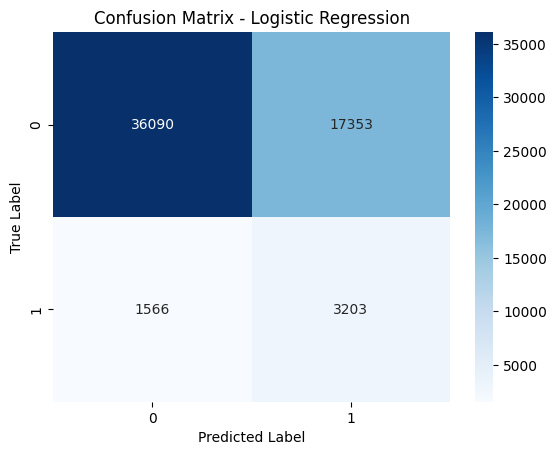

In [ ]:
# 1. Logistic Regression
logreg = LogisticRegression(C=0.1, class_weight="balanced", solver="liblinear",max_iter=1000, random_state=42)
logreg.fit(X_train, y_train.values)

train_model_cv(logreg, "Logistic Regression", X_train, y_train.values, kf, results)
evaluate_test_model(logreg, X_test, y_test, model_name="Logistic Regression")

### Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('clf', RandomForestClassifier(class_weight='balanced', random_state=42))
])

param_grid = {
    'clf__n_estimators': [100, 200],
    'clf__max_depth': [5, 10, None]
}

# 3. Cấu hình k-fold stratified
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 4. GridSearchCV
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv,
    verbose=1,
    n_jobs=-1
)

# 5. Fit GridSearchCV trên dữ liệu huấn luyện gốc (raw)
grid_search.fit(X_train_raw, y_train)

# 6. Đánh giá kết quả
print("Best parameters:", grid_search.best_params_)
print("Best CV AUC score:", grid_search.best_score_)

# 7. Dự đoán trên test
y_pred_proba = grid_search.predict_proba(X_test_raw)[:, 1]

from sklearn.metrics import roc_auc_score, classification_report
print("Test AUC score:", roc_auc_score(y_test, y_pred_proba))

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best parameters: {'clf__max_depth': 10, 'clf__n_estimators': 200}
Best CV AUC score: 0.7424897736149533
Test AUC score: 0.74562051356233



Fold 1 - Random Forest
Fold 1 AUC: 0.7460

Fold 2 - Random Forest
Fold 2 AUC: 0.7411

Fold 3 - Random Forest
Fold 3 AUC: 0.7428

Fold 4 - Random Forest
Fold 4 AUC: 0.7371

Fold 5 - Random Forest
Fold 5 AUC: 0.7447

Random Forest OOF AUC: 0.7423

Đánh giá mô hình: Random Forest
Time Taken       : 1.3313 sec
Accuracy          : 0.7411
F1 Score          : 0.2770
AUC-ROC           : 0.7456
Gini Coefficient  : 0.4912

Confusion Matrix:
 [[40251 13192]
 [ 1881  2888]]

Classification Report:
               precision    recall  f1-score   support

         0.0       0.96      0.75      0.84     53443
         1.0       0.18      0.61      0.28      4769

    accuracy                           0.74     58212
   macro avg       0.57      0.68      0.56     58212
weighted avg       0.89      0.74      0.80     58212



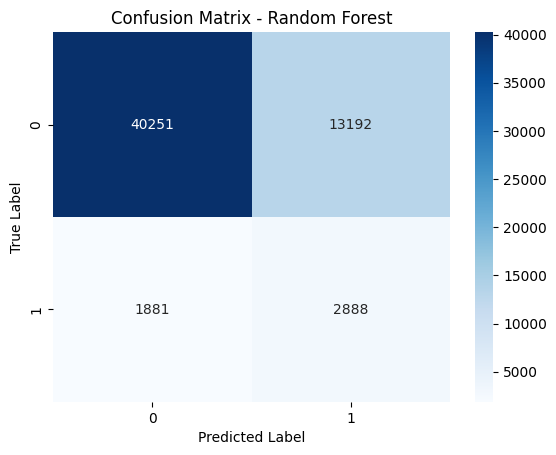

In [ ]:
# 2. Random Forest
rf = RandomForestClassifier(n_estimators=200,max_depth=10, class_weight='balanced', random_state=42)
train_model_cv(rf, "Random Forest", X_train, y_train.values, kf, results)

# Huấn luyện lại trên toàn bộ tập train trước khi evaluate
rf.fit(X_train, y_train.values)
evaluate_test_model(rf, X_test, y_test, model_name="Random Forest")

### XGBoost

In [ ]:
# Pipeline cho XGBoost
xgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),  # xử lý numeric và categorical
    ('clf', XGBClassifier(
        use_label_encoder=False,
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1,
        verbosity=0
    ))
])

# GridSearch cho XGBoost
xgb_param_grid = {
    'clf__n_estimators': [100, 200],
    'clf__max_depth': [3, 6],
    'clf__learning_rate': [0.01, 0.05, 0.1],
    'clf__subsample': [0.8, 1.0]
}

# Stratified K-Fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# GridSearchCV
grid_search_xgb = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=xgb_param_grid,
    scoring='roc_auc',
    cv=cv,
    verbose=1,
    n_jobs=-1
)
# Fit model trên tập train gốc (raw)
grid_search_xgb.fit(X_train_raw, y_train)

# Kết quả
print("Best parameters:", grid_search_xgb.best_params_)
print("Best CV AUC score:", grid_search_xgb.best_score_)

# Dự đoán trên test
y_pred_proba = grid_search_xgb.predict_proba(X_test_raw)[:, 1]

from sklearn.metrics import roc_auc_score, classification_report
print("Test AUC score:", roc_auc_score(y_test, y_pred_proba))

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best parameters: {'clf__learning_rate': 0.05, 'clf__max_depth': 6, 'clf__n_estimators': 200, 'clf__subsample': 0.8}
Best CV AUC score: 0.7578812973197536


NotFittedError: This GridSearchCV instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.


Fold 1 - XGBoost


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [16:03:14] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


Fold 1 AUC: 0.7578

Fold 2 - XGBoost


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [16:03:23] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


Fold 2 AUC: 0.7565

Fold 3 - XGBoost


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [16:03:33] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


Fold 3 AUC: 0.7613

Fold 4 - XGBoost
Fold 4 AUC: 0.7498

Fold 5 - XGBoost


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [16:03:55] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


Fold 5 AUC: 0.7588

XGBoost OOF AUC: 0.7568


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [16:04:06] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)



Đánh giá mô hình: XGBoost
Time Taken       : 0.4304 sec
Accuracy          : 0.7167
F1 Score          : 0.2790
AUC-ROC           : 0.7603
Gini Coefficient  : 0.5206

Confusion Matrix:
 [[38530 14913]
 [ 1578  3191]]

Classification Report:
               precision    recall  f1-score   support

         0.0       0.96      0.72      0.82     53443
         1.0       0.18      0.67      0.28      4769

    accuracy                           0.72     58212
   macro avg       0.57      0.70      0.55     58212
weighted avg       0.90      0.72      0.78     58212



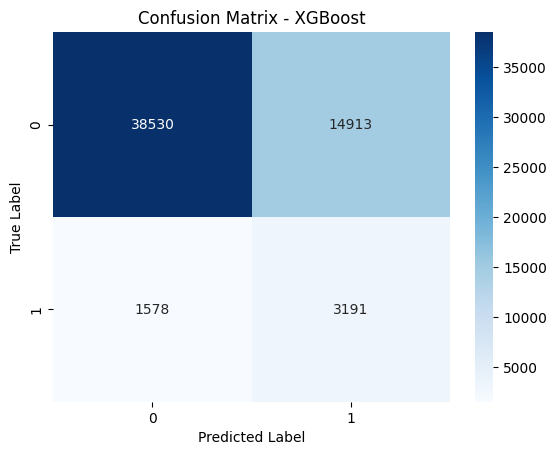

In [ ]:
# 3. XGBoost
xgb = XGBClassifier(
    scale_pos_weight=len(y_train[y_train == 0]) / len(y_train[y_train == 1]),
    n_estimators=200,
    max_depth=6,
    subsample=0.8,
    learning_rate=0.05,
    use_label_encoder=False,
    eval_metric='logloss',
    random_state=42
)
train_model_cv(xgb, "XGBoost", X_train, y_train.values, kf, results)

xgb.fit(X_train, y_train.values)
evaluate_test_model(xgb, X_test, y_test, model_name="XGBoost")

### LightGBM

In [ ]:
# 1. Pipeline cho LightGBM
lgbm_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('clf', LGBMClassifier(random_state=42))
])

# 2. GridSearch cho LightGBM
lgbm_param_grid = {
    'clf__n_estimators': [100, 200],
    'clf__max_depth': [4, 6, -1],
    'clf__learning_rate': [0.01, 0.05, 0.1],
    'clf__num_leaves': [15, 31, 63]
}

# 3. Cross-validation strategy
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 4. GridSearchCV
grid_search_lgbm = GridSearchCV(
    estimator=lgbm_pipeline,
    param_grid=lgbm_param_grid,
    scoring='roc_auc',
    cv=cv,
    verbose=1,
    n_jobs=-1
)

# 5. Fit GridSearchCV trên dữ liệu huấn luyện gốc
grid_search_lgbm.fit(X_train_raw, y_train)

# 6. Kết quả
print("Best parameters:", grid_search_lgbm.best_params_)
print("Best CV AUC score:", grid_search_lgbm.best_score_)

# 7. Dự đoán trên test
y_pred_proba_lgbm = grid_search_lgbm.predict_proba(X_test_raw)[:, 1]

# 8. Đánh giá mô hình
print("Test AUC score:", roc_auc_score(y_test, y_pred_proba_lgbm))
print("\nClassification Report:\n", classification_report(y_test, y_pred_proba_lgbm >= 0.5))

Fitting 5 folds for each of 54 candidates, totalling 270 fits
[LightGBM] [Info] Number of positive: 19076, number of negative: 213769
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.028421 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4479
[LightGBM] [Info] Number of data points in the train set: 232845, number of used features: 41
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.081926 -> initscore=-2.416465
[LightGBM] [Info] Start training from score -2.416465
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[Li


Fold 1 - LightGBM
[LightGBM] [Info] Number of positive: 15318, number of negative: 170958
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.022479 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4476
[LightGBM] [Info] Number of data points in the train set: 186276, number of used features: 41
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
Fold 1 AUC: 0.7566

Fold 2 - LightGBM
[LightGBM] [Info] Number of positive: 15246, number of negative: 171030
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.022516 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4468
[LightGBM] [Info] Number of data points in the trai

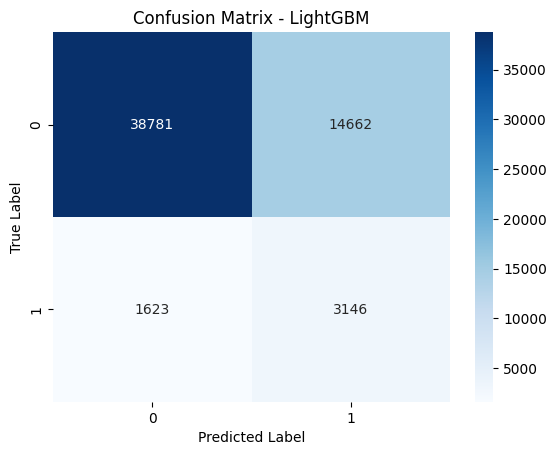

In [ ]:
# 4. LightGBM
lgbm = LGBMClassifier(
    objective='binary',
    boosting_type='gbdt',
    num_leaves=63,
    learning_rate=0.05,
    n_estimators=200,
    class_weight='balanced',
    random_state=42
)
train_model_cv(lgbm, "LightGBM", X_train, y_train.values, kf, results)

lgbm.fit(X_train, y_train.values)
evaluate_test_model(lgbm, X_test, y_test, model_name="LightGBM")

### CatBoost

In [ ]:
# 1. Pipeline cho CatBoost
catboost_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('clf', CatBoostClassifier(verbose=0, random_state=42))
])

# 2. GridSearch cho CatBoost
catboost_param_grid = {
    'clf__iterations': [100, 200],
    'clf__depth': [4, 6],
    'clf__learning_rate': [0.01, 0.005, 0.1],
}

# 3. Cross-validation strategy
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 4. GridSearchCV
grid_search = GridSearchCV(
    estimator=catboost_pipeline,
    param_grid=catboost_param_grid,
    scoring='roc_auc',
    cv=cv,
    verbose=1,
    n_jobs=-1
)

# 5. Fit GridSearchCV trên dữ liệu huấn luyện
grid_search.fit(X_train_raw, y_train)

# 6. Đánh giá kết quả
print("Best parameters:", grid_search.best_params_)
print("Best CV AUC score:", grid_search.best_score_)

# 7. Dự đoán trên tập test
y_pred_proba = grid_search.predict_proba(X_test_raw)[:, 1]

# 8. Kết quả đánh giá
print("Test AUC score:", roc_auc_score(y_test, y_pred_proba))
print("\nClassification Report:\n", classification_report(y_test, y_pred_proba >= 0.5))

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best parameters: {'clf__depth': 6, 'clf__iterations': 200, 'clf__learning_rate': 0.1}
Best CV AUC score: 0.7570504421039403
Test AUC score: 0.7576498265680238

Classification Report:
               precision    recall  f1-score   support

         0.0       0.92      1.00      0.96     53443
         1.0       0.57      0.02      0.04      4769

    accuracy                           0.92     58212
   macro avg       0.74      0.51      0.50     58212
weighted avg       0.89      0.92      0.88     58212




Fold 1 - CatBoost
Fold 1 AUC: 0.7587

Fold 2 - CatBoost
Fold 2 AUC: 0.7534

Fold 3 - CatBoost
Fold 3 AUC: 0.7599

Fold 4 - CatBoost
Fold 4 AUC: 0.7495

Fold 5 - CatBoost
Fold 5 AUC: 0.7586

CatBoost OOF AUC: 0.7559

Đánh giá mô hình: CatBoost
Time Taken       : 1.6747 sec
Accuracy          : 0.7031
F1 Score          : 0.2726
AUC-ROC           : 0.7595
Gini Coefficient  : 0.5191

Confusion Matrix:
 [[37688 15755]
 [ 1530  3239]]

Classification Report:
               precision    recall  f1-score   support

         0.0       0.96      0.71      0.81     53443
         1.0       0.17      0.68      0.27      4769

    accuracy                           0.70     58212
   macro avg       0.57      0.69      0.54     58212
weighted avg       0.90      0.70      0.77     58212



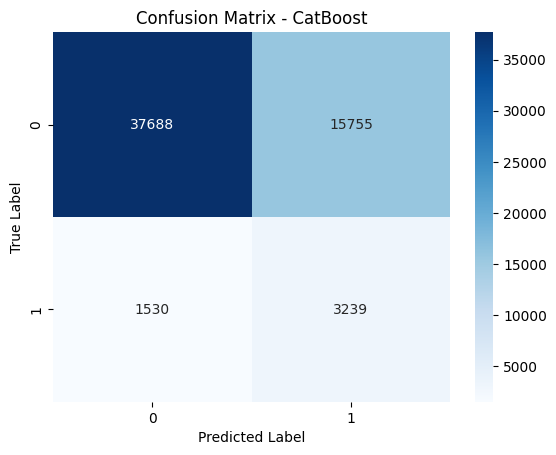

In [ ]:
# 5. CatBoost
catboost = CatBoostClassifier(
    iterations=200,
    depth=6,
    learning_rate=0.1,
    scale_pos_weight=len(y_train[y_train == 0]) / len(y_train[y_train == 1]),
    verbose=0,
    random_state=42
)
train_model_cv(catboost, "CatBoost", X_train, y_train.values, kf, results)
catboost.fit(X_train, y_train)
evaluate_test_model(catboost, X_test, y_test, model_name="CatBoost")

### Stacking LGBM, RF, and CatBoost with final estimator LR

In [ ]:
# Final estimator: Logistic Regression
final_lr = LogisticRegression(solver='liblinear', class_weight='balanced', random_state=42)

# Stacking model
stacking_clf = StackingClassifier(
    estimators=[
        ('lgbm', lgbm),
        ('rf', rf),
        ('catboost', catboost)
    ],
    final_estimator=final_lr,
    cv=5,
    n_jobs=-1,
    passthrough=False
)

# Full pipeline
stacking_pipeline_1 = Pipeline(steps=[
    ('preprocessor', preprocessor),  # ColumnTransformer: numeric + categorical
    ('stack', stacking_clf)
])


In [ ]:
stacking_pipeline_1.fit(X_train_raw, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['EXT_SOURCE_MEAN',
                                                   'AMT_INCOME_TOTAL',
                                                   'AMT_CREDIT', 'AMT_ANNUITY',
                                                   'BURO_AMT_CREDIT_SUM_DEBT_MEAN',
                                                   'BURO_AMT_CREDIT_SUM_MEAN',
                                                   'BURO_AMT_CREDIT_MAX_OVERDUE_MEAN',
                                                   'PREV_AMT_ANNUITY_MEAN',
                                                   'PREV...
                                                                learning_rate=0.05,
                                                                n_estimators=200,
                                                                num_leaves=63,
                                                                objective='binary',
                                                                random_state=42)),
                                                ('rf',
                                                 RandomForestClassifier(class_weight='balanced',
                                                                        max_depth=10,
                                                                        n_estimators=200,
                                                                        random_state=42)),
                                                ('catboost',
                                                 <catboost.core.CatBoostClassifier object at 0x79feb1393610>)],
                                    final_estimator=LogisticRegression(class_weight='balanced',
                                                                       random_state=42,
                                                                       solver='liblinear'),
                                    n_jobs=-1))])

Đánh giá mô hình STACKING
Accuracy          : 0.6897
F1 Score          : 0.2695
AUC-ROC           : 0.7615
Gini Coefficient  : 0.5229
Confusion Matrix:
 [[36813 16630]
 [ 1436  3333]]

Classification Report:
               precision    recall  f1-score   support

         0.0       0.96      0.69      0.80     53443
         1.0       0.17      0.70      0.27      4769

    accuracy                           0.69     58212
   macro avg       0.56      0.69      0.54     58212
weighted avg       0.90      0.69      0.76     58212



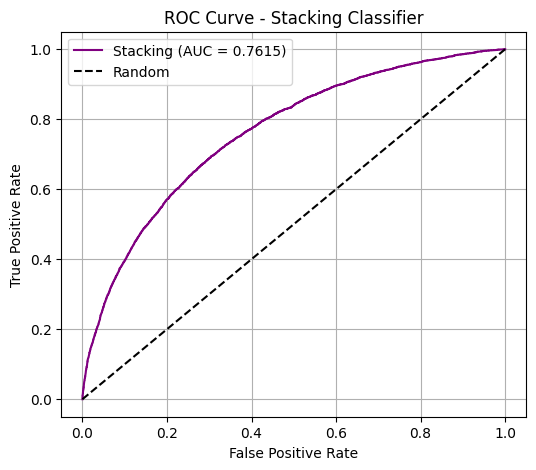

In [ ]:
# Dự đoán xác suất và nhãn
y_pred_proba = stacking_pipeline_1.predict_proba(X_test_raw)[:, 1]
y_pred = (y_pred_proba >= 0.5).astype(int)


# Đánh giá
auc = roc_auc_score(y_test, y_pred_proba)
gini = 2 * auc - 1
f1 = f1_score(y_test, y_pred)
acc = accuracy_score(y_test, y_pred)

print("Đánh giá mô hình STACKING")
print(f"Accuracy          : {acc:.4f}")
print(f"F1 Score          : {f1:.4f}")
print(f"AUC-ROC           : {auc:.4f}")
print(f"Gini Coefficient  : {gini:.4f}")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# --- ROC Curve ---
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Stacking (AUC = {auc:.4f})", color='purple')
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Stacking Classifier")
plt.legend()
plt.grid()
plt.show()


###  Stacking LGBM, RF, and XGBoost with final estimator LR

In [ ]:
# Stacking Classifier
stacking_clf = StackingClassifier(
    estimators=[
        ('lgbm', lgbm),
        ('rf', rf),
        ('xgb', xgb)
    ],
    final_estimator=LogisticRegression(solver='liblinear', class_weight='balanced', random_state=42),
    cv=5,
    n_jobs=-1,
    passthrough=False  # Nếu muốn đưa input ban đầu vào final model → True
)

# Full Pipeline
stacking_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),  # xử lý numeric & categorical
    ('stack', stacking_clf)
])

In [ ]:
stacking_pipeline.fit(X_train_raw, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['EXT_SOURCE_MEAN',
                                                   'AMT_INCOME_TOTAL',
                                                   'AMT_CREDIT', 'AMT_ANNUITY',
                                                   'BURO_AMT_CREDIT_SUM_DEBT_MEAN',
                                                   'BURO_AMT_CREDIT_SUM_MEAN',
                                                   'BURO_AMT_CREDIT_MAX_OVERDUE_MEAN',
                                                   'PREV_AMT_ANNUITY_MEAN',
                                                   'PREV...
                                                               max_cat_threshold=None,
                                                               max_cat_to_onehot=None,
                                                               max_delta_step=None,
                                                               max_depth=6,
                                                               max_leaves=None,
                                                               min_child_weight=None,
                                                               missing=nan,
                                                               monotone_constraints=None,
                                                               multi_strategy=None,
                                                               n_estimators=200,
                                                               n_jobs=None,
                                                               num_parallel_tree=None,
                                                               random_state=42, ...))],
                                    final_estimator=LogisticRegression(class_weight='balanced',
                                                                       random_state=42,
                                                                       solver='liblinear'),
                                    n_jobs=-1))])

Đánh giá mô hình STACKING
Accuracy          : 0.6872
F1 Score          : 0.2680
AUC-ROC           : 0.7612
Gini Coefficient  : 0.5224
Confusion Matrix:
 [[36670 16773]
 [ 1436  3333]]

Classification Report:
               precision    recall  f1-score   support

         0.0       0.96      0.69      0.80     53443
         1.0       0.17      0.70      0.27      4769

    accuracy                           0.69     58212
   macro avg       0.56      0.69      0.53     58212
weighted avg       0.90      0.69      0.76     58212



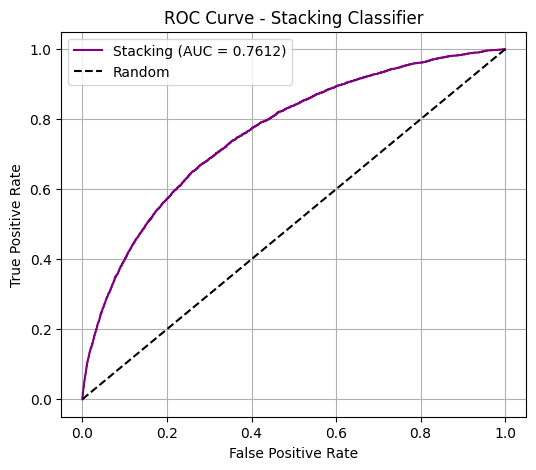

In [ ]:
# Dự đoán xác suất và nhãn
y_pred_proba = stacking_pipeline.predict_proba(X_test_raw)[:, 1]
y_pred = (y_pred_proba >= 0.5).astype(int)


# Đánh giá
auc = roc_auc_score(y_test, y_pred_proba)
gini = 2 * auc - 1
f1 = f1_score(y_test, y_pred)
acc = accuracy_score(y_test, y_pred)

print("Đánh giá mô hình STACKING")
print(f"Accuracy          : {acc:.4f}")
print(f"F1 Score          : {f1:.4f}")
print(f"AUC-ROC           : {auc:.4f}")
print(f"Gini Coefficient  : {gini:.4f}")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# --- ROC Curve ---
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Stacking (AUC = {auc:.4f})", color='purple')
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Stacking Classifier")
plt.legend()
plt.grid()
plt.show()

### Voting LightGBM, Random Forest, và CatBoost

In [ ]:
# VotingClassifier (soft voting)
voting_clf = VotingClassifier(
    estimators=[
        ('lgbm', lgbm),
        ('rf', rf),
        ('catboost', catboost)
    ],
    voting='soft',   # dùng xác suất trung bình
    n_jobs=-1
)
voting_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),   # xử lý numeric + categorical features
    ('voting', voting_clf)
])

In [ ]:
# Train
voting_pipeline.fit(X_train_raw, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['EXT_SOURCE_MEAN',
                                                   'AMT_INCOME_TOTAL',
                                                   'AMT_CREDIT', 'AMT_ANNUITY',
                                                   'BURO_AMT_CREDIT_SUM_DEBT_MEAN',
                                                   'BURO_AMT_CREDIT_SUM_MEAN',
                                                   'BURO_AMT_CREDIT_MAX_OVERDUE_MEAN',
                                                   'PREV_AMT_ANNUITY_MEAN',
                                                   'PREV...
                 VotingClassifier(estimators=[('lgbm',
                                               LGBMClassifier(class_weight='balanced',
                                                              learning_rate=0.05,
                                                              n_estimators=200,
                                                              num_leaves=63,
                                                              objective='binary',
                                                              random_state=42)),
                                              ('rf',
                                               RandomForestClassifier(class_weight='balanced',
                                                                      max_depth=10,
                                                                      n_estimators=200,
                                                                      random_state=42)),
                                              ('catboost',
                                               <catboost.core.CatBoostClassifier object at 0x79feb1393610>)],
                                  n_jobs=-1, voting='soft'))])

Đánh giá mô hình Voting
Accuracy          : 0.7208
F1 Score          : 0.2759
AUC-ROC           : 0.7598
Gini Coefficient  : 0.5197
Confusion Matrix:
 [[38865 14578]
 [ 1673  3096]]

Classification Report:
               precision    recall  f1-score   support

         0.0       0.96      0.73      0.83     53443
         1.0       0.18      0.65      0.28      4769

    accuracy                           0.72     58212
   macro avg       0.57      0.69      0.55     58212
weighted avg       0.89      0.72      0.78     58212



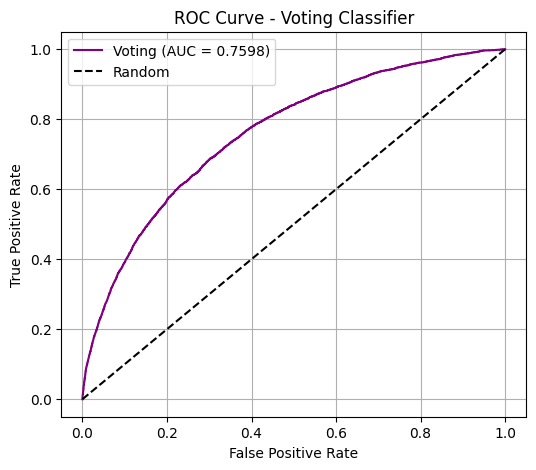

In [ ]:
# Predict
y_pred_proba = voting_pipeline.predict_proba(X_test_raw)[:, 1]
y_pred = (y_pred_proba >= 0.5).astype(int)

# Đánh giá
auc = roc_auc_score(y_test, y_pred_proba)
gini = 2 * auc - 1
f1 = f1_score(y_test, y_pred)
acc = accuracy_score(y_test, y_pred)

print("Đánh giá mô hình Voting")
print(f"Accuracy          : {acc:.4f}")
print(f"F1 Score          : {f1:.4f}")
print(f"AUC-ROC           : {auc:.4f}")
print(f"Gini Coefficient  : {gini:.4f}")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# --- ROC Curve ---
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Voting (AUC = {auc:.4f})", color='purple')
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Voting Classifier")
plt.legend()
plt.grid()
plt.show()

## Classifier model comparison

In [ ]:
models = [
    ("Logistic Regression", logreg),
    ("Random Forest", rf),
    ("XGBoost", xgb),
    ("LightGBM", lgbm),
    ("CatBoost", catboost),
    ("Stacking_LGBM_RF_Cat", stacking_pipeline_1),
    ("Stacking_LGBM_RF_XGB", stacking_pipeline),
    ("Voting_LGBM_RF_Cat", voting_pipeline)
]

In [ ]:
# Danh sách lưu kết quả
f1_scores = []
recall_scores = []
precision_scores = []
auc_scores = []
gini_scores = []

# Duyệt qua từng mô hình
for name, model in models:
    print(f"\n--- Đang đánh giá: {name} ---")

    # Nếu là pipeline (có preprocessor) thì dùng dữ liệu gốc
    X_eval = X_test_raw if isinstance(model, Pipeline) else X_test

    # Dự đoán
    y_pred_proba = model.predict_proba(X_eval)[:, 1]
    y_pred = model.predict(X_eval)

    # Tính metrics
    f1 = f1_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_pred_proba)
    gini = 2 * auc - 1

    # In kết quả
    print(f"F1 Score       : {f1:.4f}")
    print(f"Recall         : {recall:.4f}")
    print(f"Precision      : {precision:.4f}")
    print(f"AUC-ROC        : {auc:.4f}")
    print(f"Gini           : {gini:.4f}")

    # Lưu lại
    f1_scores.append(f1)
    recall_scores.append(recall)
    precision_scores.append(precision)
    auc_scores.append(auc)
    gini_scores.append(gini)



--- Đang đánh giá: Logistic Regression ---
F1 Score       : 0.2530
Recall         : 0.6716
Precision      : 0.1558
AUC-ROC        : 0.7343
Gini           : 0.4687

--- Đang đánh giá: Random Forest ---
F1 Score       : 0.2770
Recall         : 0.6056
Precision      : 0.1796
AUC-ROC        : 0.7456
Gini           : 0.4912

--- Đang đánh giá: XGBoost ---
F1 Score       : 0.2790
Recall         : 0.6691
Precision      : 0.1763
AUC-ROC        : 0.7603
Gini           : 0.5206

--- Đang đánh giá: LightGBM ---
F1 Score       : 0.2787
Recall         : 0.6597
Precision      : 0.1767
AUC-ROC        : 0.7598
Gini           : 0.5196

--- Đang đánh giá: CatBoost ---
F1 Score       : 0.2726
Recall         : 0.6792
Precision      : 0.1705
AUC-ROC        : 0.7595
Gini           : 0.5191

--- Đang đánh giá: Stacking_LGBM_RF_Cat ---
F1 Score       : 0.2695
Recall         : 0.6989
Precision      : 0.1670
AUC-ROC        : 0.7615
Gini           : 0.5229

--- Đang đánh giá: Stacking_LGBM_RF_XGB ---
F1 Score  

/tmp/ipython-input-107-3078609321.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  s1.set_xticklabels(s1.get_xticklabels(), rotation=90)
/tmp/ipython-input-107-3078609321.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  s2.set_xticklabels(s2.get_xticklabels(), rotation=90)
/tmp/ipython-input-107-3078609321.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  s3.set_xticklabels(s3.get_xticklabels(), rotation=90)
/tmp/ipython-input-107-3078609321.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  s4.set_xticklabels(s4.get_xticklabels(), rotation=90)
/tmp/ipython-input-107-3078609321.py:43: UserWarning: tight_layout not applied: number of rows in su

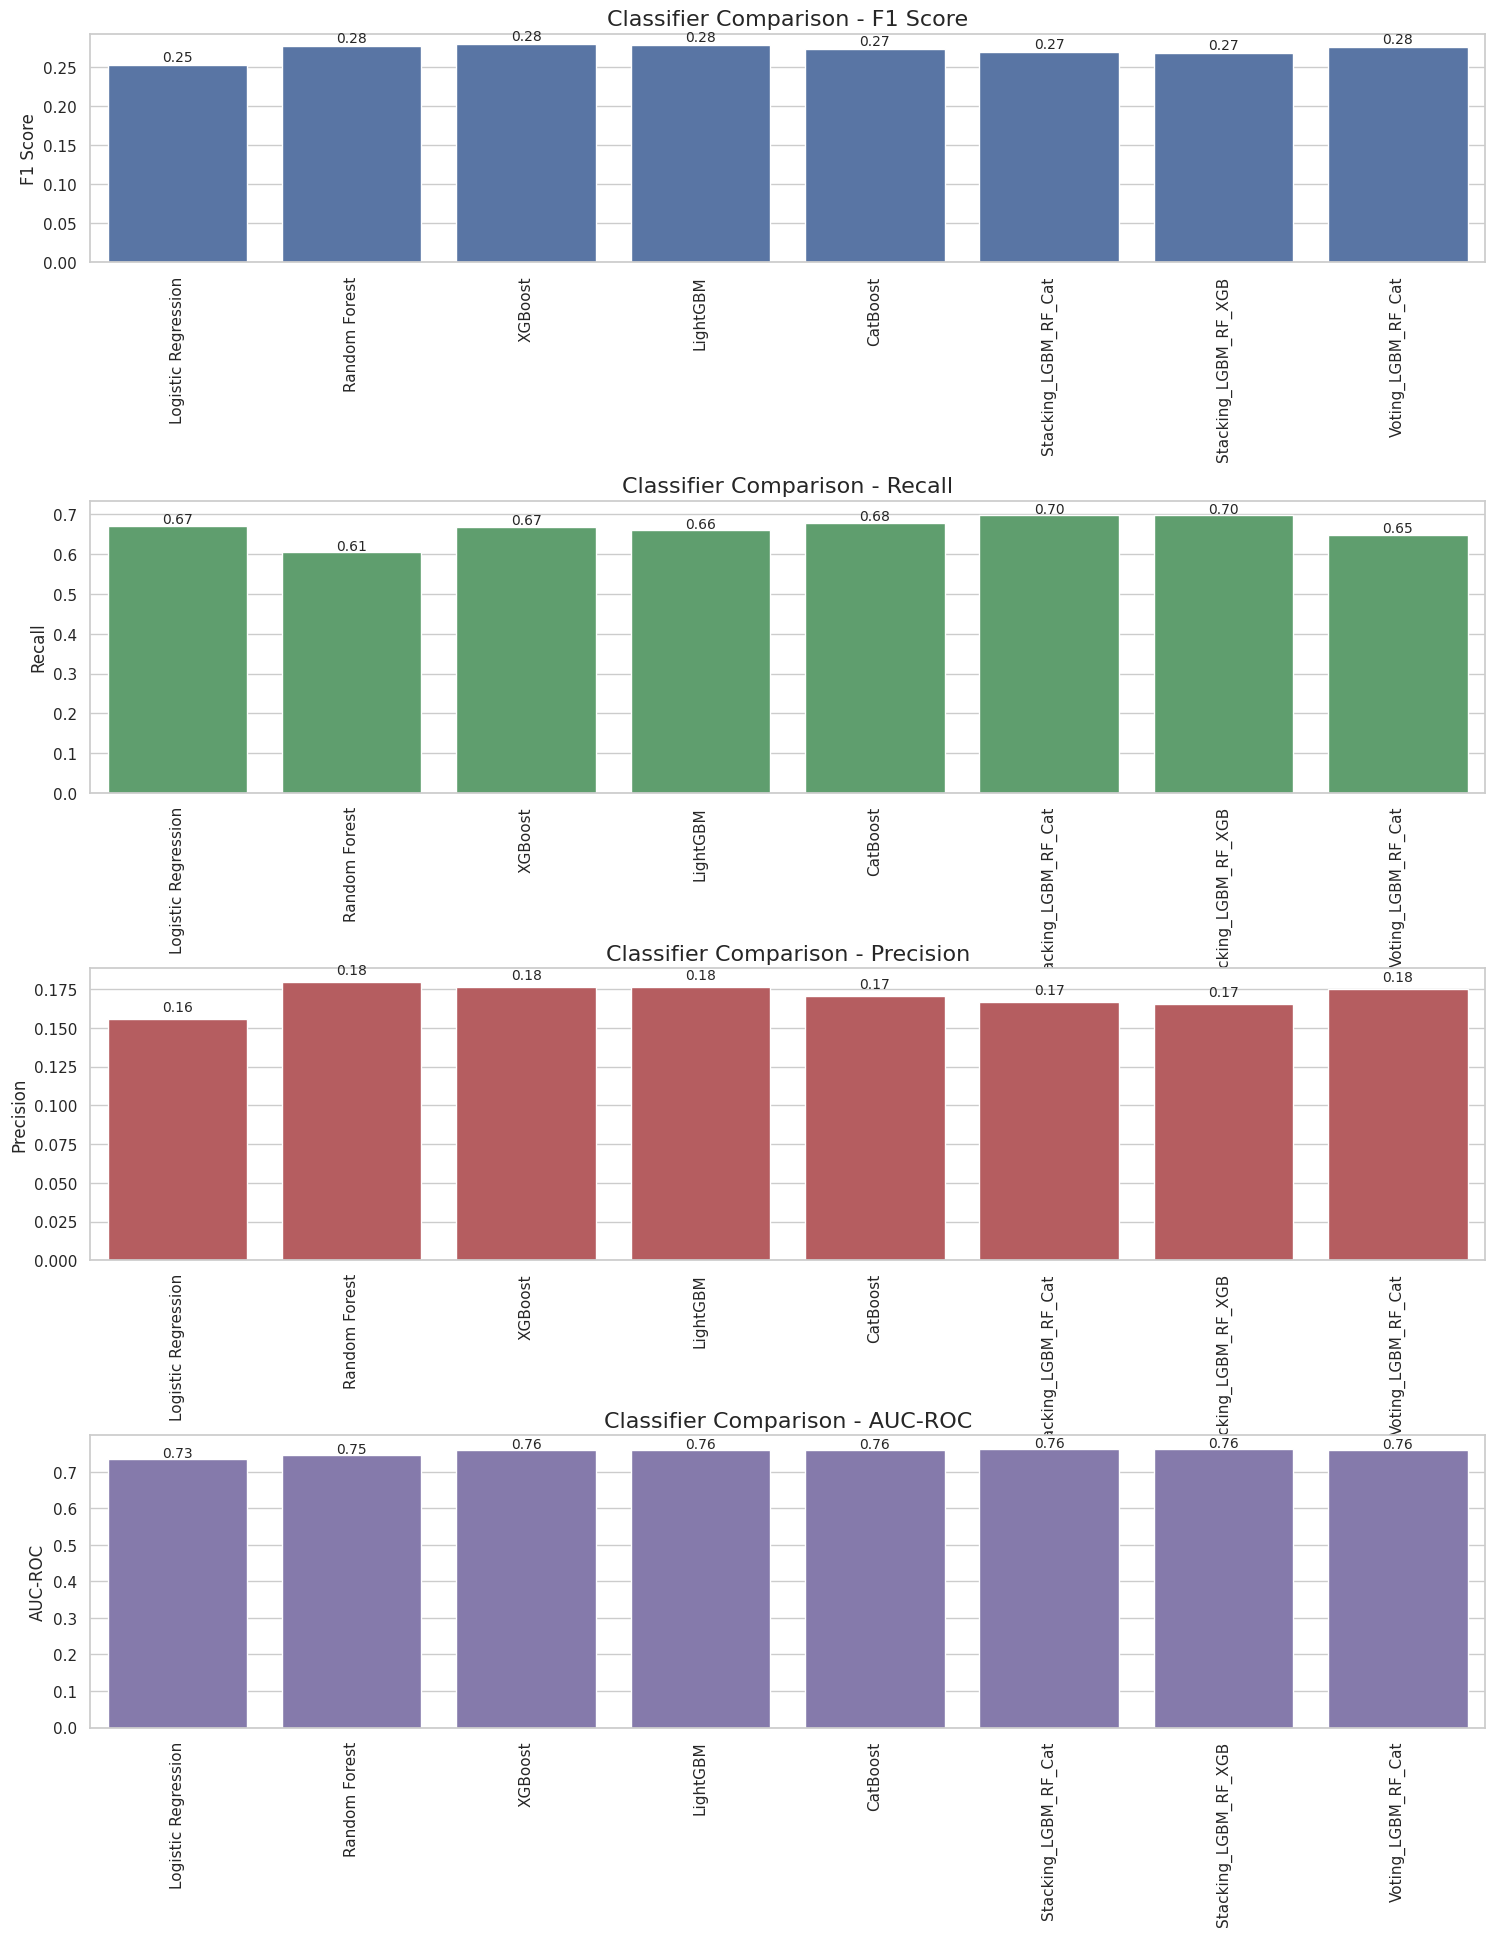

In [ ]:
classifier_names = [name for name, _ in models]

sns.set(style="whitegrid", palette="colorblind")
plt.figure(figsize=(18, 22))

# F1
plt.subplot(511)
plt.title("Classifier Comparison - F1 Score", fontsize=16)
s1 = sns.barplot(x=classifier_names, y=f1_scores, color="#4C72B0")
s1.set_xticklabels(s1.get_xticklabels(), rotation=90)
plt.ylabel('F1 Score')
for i, v in enumerate(f1_scores):
    plt.text(i, v + 0.005, f"{v:.2f}", ha='center', fontsize=10)

# Recall
plt.subplot(412)
plt.title("Classifier Comparison - Recall", fontsize=16)
s2 = sns.barplot(x=classifier_names, y=recall_scores, color="#55A868")
s2.set_xticklabels(s2.get_xticklabels(), rotation=90)
plt.ylabel('Recall')
for i, v in enumerate(recall_scores):
    plt.text(i, v + 0.005, f"{v:.2f}", ha='center', fontsize=10)

# Precision
plt.subplot(413)
plt.title("Classifier Comparison - Precision", fontsize=16)
s3 = sns.barplot(x=classifier_names, y=precision_scores, color="#C44E52")
s3.set_xticklabels(s3.get_xticklabels(), rotation=90)
plt.ylabel('Precision')
for i, v in enumerate(precision_scores):
    plt.text(i, v + 0.005, f"{v:.2f}", ha='center', fontsize=10)

# AUC-ROC
plt.subplot(414)
plt.title("Classifier Comparison - AUC-ROC", fontsize=16)
s4 = sns.barplot(x=classifier_names, y=auc_scores, color="#8172B3")
s4.set_xticklabels(s4.get_xticklabels(), rotation=90)
plt.ylabel('AUC-ROC')
for i, v in enumerate(auc_scores):
    plt.text(i, v + 0.005, f"{v:.2f}", ha='center', fontsize=10)

plt.subplots_adjust(hspace=0.6)
plt.tight_layout()
plt.show()

In [ ]:

result_df = pd.DataFrame({
    "Model": [name for name, _ in models],
    "F1 Score": f1_scores,
    "Recall": recall_scores,
    "Precision": precision_scores,
    "AUC-ROC": auc_scores,
    "Gini": gini_scores
})

display(result_df.sort_values("Gini", ascending=False))

,Model,F1 Score,Recall,Precision,AUC-ROC,Gini
5,Stacking_LGBM_RF_Cat,0.269529,0.698889,0.166959,0.761460,0.522920
6,Stacking_LGBM_RF_XGB,0.267980,0.698889,0.165771,0.761177,0.522354
2,XGBoost,0.279019,0.669113,0.176259,0.760288,0.520575
7,Voting_LGBM_RF_Cat,0.275899,0.649193,0.175173,0.759838,0.519676
3,LightGBM,0.278691,0.659677,0.176662,0.759779,0.519558
4,CatBoost,0.272609,0.679178,0.170528,0.759545,0.519089
1,Random Forest,0.277040,0.605578,0.179602,0.745621,0.491241
0,Logistic Regression,0.252952,0.671629,0.155818,0.734331,0.468662


## Mục tiêu đánh giá mô hình

1. **F1 Score cao**  
   → Cân bằng giữa phát hiện đúng khách hàng vỡ nợ (Recall) và hạn chế cảnh báo sai (Precision).  
   → F1 càng cao, mô hình càng hiệu quả trong việc **nhận diện đúng khách hàng rủi ro mà không đánh nhầm quá nhiều khách hàng tiềm năng**.

2. **Recall cao (Sensitivity)**  
   → Tỷ lệ khách hàng vỡ nợ thực sự mà mô hình phát hiện đúng.  
   → Càng cao càng **giảm rủi ro bỏ sót**, giúp ngân hàng phòng ngừa tổn thất.

3. **Precision hợp lý**  
   → Trong số các khách hàng được mô hình dự đoán là vỡ nợ, bao nhiêu phần trăm là đúng.  
   → Giúp giảm số lượng cảnh báo nhầm gây phiền hà hoặc từ chối oan.

4. **AUC-ROC cao**  
   → Mô hình có khả năng phân biệt tốt giữa khách hàng có và không có rủi ro.  
   → AUC > 0.75 là mức rất tốt.

5. **Gini Coefficient**  
   → Thước đo phổ biến trong ngân hàng để đánh giá mô hình.  
   → Gini = 2 × AUC – 1.  
   → Gini > 0.5 là chấp nhận được để triển khai thực tế.

6. **Tính dễ triển khai & giải thích (XAI)**  
   → Ưu tiên các mô hình có thể tích hợp SHAP, dễ giải thích cho nhân viên tín dụng hoặc phòng kiểm soát rủi ro.

---

## Kết quả mô hình

### 1. XGBoost

- **F1 Score = 0.2790**  
  → Mức hiệu quả tổng thể ~28% trong việc phát hiện đúng người vỡ nợ và hạn chế cảnh báo nhầm.

- **Recall = 0.6691**  
  → Trong 100 khách hàng **thực sự vỡ nợ**, mô hình phát hiện đúng **66 người**, còn **bỏ sót 34 người**.

- **Precision = 0.176**  
  → Trong 100 khách hàng mà mô hình dự đoán là vỡ nợ, chỉ có **~18 người thật sự vỡ nợ**, còn lại **82 người là cảnh báo sai**.

- **AUC-ROC = 0.760**  
  → Với mỗi cặp gồm một người vỡ nợ và một người không, mô hình có **76% khả năng xếp đúng người có rủi ro cao hơn**.

- **Gini = 0.520**  
  → Mô hình phân biệt khách hàng rủi ro tốt hơn ngẫu nhiên **52%**, vượt ngưỡng triển khai thực tế.

---

### 2. LightGBM

- **F1 Score = 0.2787**
- **Recall = 0.6596**
- **Precision = 0.177**
- **AUC-ROC = 0.759**
- **Gini = 0.519**

→ Các chỉ số tương đương XGBoost, cho thấy LightGBM cũng là một mô hình rất mạnh, có thể được cân nhắc tùy vào tốc độ huấn luyện, yêu cầu triển khai hoặc khả năng giải thích.

---
Bước tiếp theo:
- Áp dụng **tối ưu threshold** để cải thiện F1 score.
- Đánh giá lại trên tập validation/test với threshold mới.
- Triển khai **SHAP** để trực quan hóa nguyên nhân dự đoán vỡ nợ.


### Save model

In [ ]:
import joblib

In [ ]:
# Thư mục đích
save_dir = "/content/drive/MyDrive/KhoaLuan/Model_File_1/"
os.makedirs(save_dir, exist_ok=True)

# Lưu từng model
for name, model in models:
    file_path = os.path.join(save_dir, f"{name.replace(' ', '_')}.pkl")
    try:
        joblib.dump(model, file_path)
        print(f"✅ Đã lưu: {file_path}")
    except Exception as e:
        print(f"❌ Lỗi khi lưu {name}: {e}")


✅ Đã lưu: /content/drive/MyDrive/KhoaLuan/Logistic_Regression.pkl
✅ Đã lưu: /content/drive/MyDrive/KhoaLuan/Random_Forest.pkl
✅ Đã lưu: /content/drive/MyDrive/KhoaLuan/XGBoost.pkl
✅ Đã lưu: /content/drive/MyDrive/KhoaLuan/LightGBM.pkl
✅ Đã lưu: /content/drive/MyDrive/KhoaLuan/CatBoost.pkl
✅ Đã lưu: /content/drive/MyDrive/KhoaLuan/Stacking_LGBM_RF_Cat.pkl
✅ Đã lưu: /content/drive/MyDrive/KhoaLuan/Stacking_LGBM_RF_XGB.pkl
✅ Đã lưu: /content/drive/MyDrive/KhoaLuan/Voting_LGBM_RF_Cat.pkl


### DEEP LEARNING

| MODEL     | F1 SCORE | RECALL | PRECISION | AUC-ROC | GINI   |
|-----------|----------|--------|-----------|---------|--------|
| LSTM      | 0.23     | 0.65   | 0.14      | 0.7053  | 0.4107 |
| MLP | 0.26     | 0.67   | 0.16      | 0.7387  | 0.4774 |
| BILSTM    | 0.24     | 0.62   | 0.15      | 0.7118  | 0.4237 |
| CNN1D     | 0.25     | 0.65   | 0.16      | 0.7268  | 0.4536 |

- Trong bài toán dự đoán khả năng vỡ nợ của khách hàng, dữ liệu huấn luyện có sự mất cân bằng nghiêm trọng, trong đó số lượng khách hàng không vỡ nợ (class 0) chiếm tỷ lệ lớn so với khách hàng vỡ nợ (class 1). Do đó, việc đánh giá mô hình cần tập trung vào khả năng nhận diện chính xác nhóm khách hàng rủi ro (class 1) thay vì chỉ dựa vào độ chính xác tổng thể.

- Các chỉ số chính được sử dụng để đánh giá mô hình:
Recall (class 1): Ưu tiên hàng đầu vì nó cho biết khả năng phát hiện đúng khách hàng vỡ nợ.

    - Precision (class 1): Cho biết tính chính xác trong các cảnh báo vỡ nợ.

    - F1 Score (class 1): Cân bằng giữa precision và recall, phù hợp với bài toán mất cân bằng.

    - AUC-ROC & Gini: Đánh giá tổng thể năng lực phân biệt của mô hình giữa hai
- Nhận xét từng mô hình
* MLP_Keras
    - Là mô hình có hiệu suất tốt nhất trong tất cả các mô hình đã thử nghiệm.
    - Đạt F1 Score cao nhất (0.26) và Recall cao nhất (0.67) cho class 1, nghĩa là mô hình nhận diện tốt các khách hàng vỡ nợ.
    - AUC-ROC (0.7387) và Gini (0.4774) cũng cao nhất, chứng tỏ khả năng phân biệt hai lớp rất tốt.

Là mô hình đơn giản, dễ huấn luyện và triển khai, rất phù hợp trong các ứng dụng thực tế có yêu cầu phát hiện sớm rủi ro.

* CNN1D
Hiệu năng tương đương với MLP_Keras, F1 Score đạt 0.25, Recall 0.65.

AUC-ROC (0.7268) và Gini (0.4536) cũng rất ấn tượng.

Có khả năng khai thác tốt cấu trúc thứ tự của đặc trưng, phù hợp nếu dữ liệu đầu vào có yếu tố chuỗi hoặc liên quan đến thời gian.

Có thể cân nhắc dùng thay thế MLP nếu muốn tận dụng kiến trúc mạng tích chập.

🔹 BiLSTM
Là mô hình RNN 2 chiều, cho phép khai thác cả chiều trước và sau của dữ liệu.

Tuy nhiên, F1 Score chỉ đạt 0.24, thấp hơn MLP và CNN1D.

Recall 0.62, AUC-ROC 0.7118, cho thấy hiệu quả không vượt trội như kỳ vọng.

Thích hợp hơn nếu dữ liệu có yếu tố thời gian hoặc chuỗi rõ ràng, nhưng trong bài toán này, không phát huy được lợi thế.

🔹 LSTM
Là mô hình có hiệu quả thấp nhất trong nhóm.

F1 Score chỉ 0.23, Precision thấp nhất (0.14), cho thấy tỷ lệ cảnh báo sai còn cao.

AUC-ROC 0.7053, Gini 0.4107 cũng thấp nhất.

Có thể bị overfitting hoặc không phù hợp với dạng dữ liệu hiện tại, do không có yếu tố tuần tự mạnh mẽ.

🧠 Tổng kết
MLP_Keras là mô hình tốt nhất cho bài toán này: đơn giản, chính xác cao, hiệu quả trên cả recall và AUC.

CNN1D là lựa chọn thay thế đáng cân nhắc, đặc biệt nếu có đặc trưng dạng chuỗi.

BiLSTM và LSTM không đem lại hiệu quả vượt trội, trừ khi có dữ liệu chuỗi mạnh mẽ hơn.

Việc sử dụng F1 Score, Recall và AUC-ROC là cần thiết trong bài toán mất cân bằng để tránh bỏ sót khách hàng rủi ro.